Project : Medical insurance cost Prediction

Dataset: insurance.csv

Kaggle link: 

Process: EDA -> preprocessing -> baselinemodel -> model selection(cv) -> tuning(gridsearchcv) -> final evaluation -> inference

1.set up

In [25]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.compose import TransformedTargetRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)


In [27]:
# configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x: 3f}" )
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

RANDOM_STATE = 42
CSV_PATH = "insurance.csv"
TARGET_COL = "charges"

Load Data

In [28]:
df = pd.read_csv(CSV_PATH)

In [29]:
print("DataFrame shape:", df.shape)

DataFrame shape: (1338, 7)


In [30]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900000,0,yes,southwest,16884.924000
1,18,male,33.770000,1,no,southeast,1725.552300
2,28,male,33.000000,3,no,southeast,4449.462000
3,33,male,22.705000,0,no,northwest,21984.470610
4,32,male,28.880000,0,no,northwest,3866.855200


Exploratory Data Analysis (EDA)

In [31]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Column  feature type
age     numerical(continuous)
sex     categorical
bmi     numerical(continuous)
children numerical(discrete)
smoker categorical(binary)
region (categorical)
charges (numerical)(continuous, target)

In [32]:
# basis dataset overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [33]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Target column:", TARGET_COL)
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Target column: charges
Numerical columns: ['age', 'bmi', 'children', 'charges']
Categorical columns: ['sex', 'smoker', 'region']


In [34]:
#missing values analysis
print("\nMissing values per column:")
print(df.isna().sum())


Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [35]:
#check presence of encoded missing values
for col in df.columns:
    print(df[col].value_counts().head(20)) 

age
18    69
19    68
50    29
51    29
47    29
46    29
45    29
20    29
48    29
52    29
22    28
49    28
54    28
53    28
21    28
26    28
24    28
25    28
28    28
27    28
Name: count, dtype: int64
sex
male      676
female    662
Name: count, dtype: int64
bmi
32.300000    13
28.310000     9
30.495000     8
30.875000     8
31.350000     8
30.800000     8
34.100000     8
28.880000     8
33.330000     7
35.200000     7
25.800000     7
32.775000     7
27.645000     7
32.110000     7
38.060000     7
25.460000     7
30.590000     7
27.360000     7
24.320000     7
34.800000     7
Name: count, dtype: int64
children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64
smoker
no     1064
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64
charges
1639.563100     2
16884.924000    1
29330.983150    1
2221.564450     1
19798.054550    1
13063.883000    1
13555.004900    1
4

Inference no missing values

In [36]:
#duplicates
duplicate_mask = df.duplicated()
num_duplicates = duplicate_mask.sum()
print("Number of duplicate rows:", num_duplicates)

#optional drop duplicates if present
df = df.drop_duplicates()
print("shape after dropping duplicates:", df.shape)

Number of duplicate rows: 1
shape after dropping duplicates: (1337, 7)


In [37]:
#descriptive stat
df[num_cols].describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [38]:
# descriptive stat Traspoe
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1337.000000,39.222139,14.044333,18.000000,27.000000,39.000000,51.000000,64.000000
bmi,1337.000000,30.663452,6.100468,15.960000,26.290000,30.400000,34.700000,53.130000
children,1337.000000,1.095737,1.205571,0.000000,0.000000,1.000000,2.000000,5.000000
charges,1337.000000,13279.121487,12110.359656,1121.873900,4746.344000,9386.161300,16657.717450,63770.428010


In [39]:
# categorical columns analysis
for col in  cat_cols:
    print(df[col].value_counts())

sex
male      675
female    662
Name: count, dtype: int64
smoker
no     1063
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


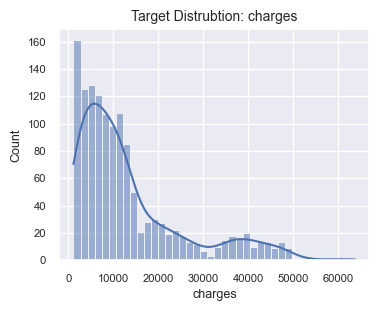

In [40]:
# target column distrubtion
plt.figure(figsize=(4,3))
sns.histplot(df[TARGET_COL], bins=40, kde=True)
plt.title(f"Target Distrubtion: {TARGET_COL}")
plt.xlabel(TARGET_COL)
plt.show()

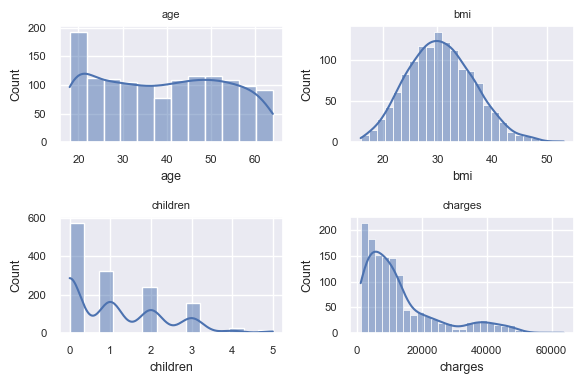

In [41]:
#histogram plot - distrubtion
fig, axes = plt.subplots(2,2, figsize=(6, 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)

plt.tight_layout()
plt.show()

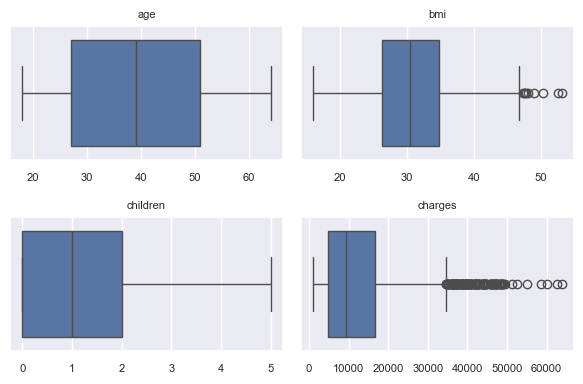

In [42]:
#outliers analaysis - boxplot
fig, axes = plt.subplots(2, 2, figsize=(6, 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

# outliers are real value so we no need to replace with median values . And better understanding we will implement target anlaysis 

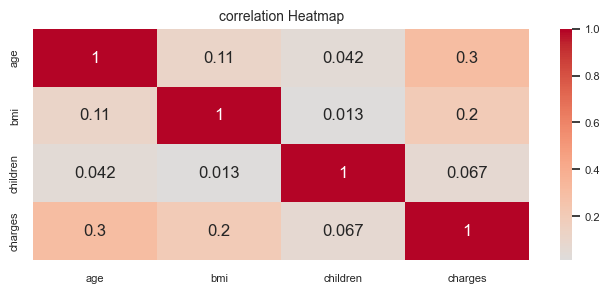

In [43]:
#identiy presence of highly correlated columns & feature relationships
plt.figure(figsize=(8, 3))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)
plt.title("correlation Heatmap")
plt.show()

Note:- we dont have much correlated columns

In [44]:
# correlation with target
corr_with_target = df[num_cols].corr()[TARGET_COL].sort_values(ascending=False)
print("\nCorrelation with target:")
print(corr_with_target)


Correlation with target:
charges     1.000000
age         0.298308
bmi         0.198401
children    0.067389
Name: charges, dtype: float64


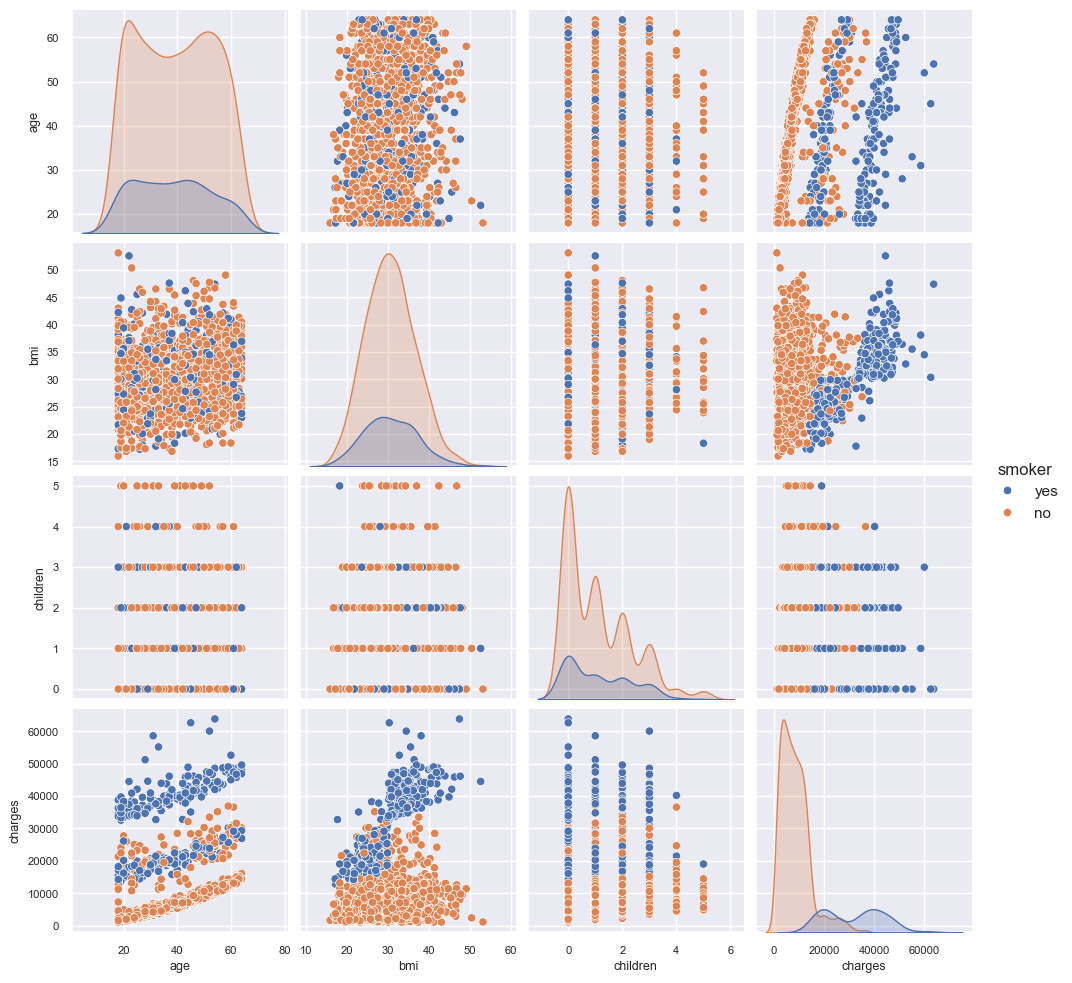

In [47]:
pairplot_cols = num_cols + ["smoker"]

df_pair = df[pairplot_cols].dropna()

sns.pairplot(df_pair, hue="smoker")
plt.show()

Key Insight from EDA
Dataset contains amix of numerical features(age, bmi, children) and categorical features(sex, smoker, region)
no missing values detected in any column
Target variable charges is highly right-skewed with a small number of exterme high-cost outliers
smoker status shows avery strong separation in the charges distribution
age and bmi show moderate positve correlation with charges
no severe multicollinearity among numerical features
outliers are prominent in charges(and to aless extenet BMI), especially for smolers


processing & evalution plan
No misiing value imputation required
one-hot encode categorical variavles(sex, smoker, region)
features scaling applied for linear and regularized models
no aggressive outlier removal, to preserve real - world-high-cost medicalcases
use pipelines and columntransormer to prevent data leakge
Baseline model using linear regression
model comparsion using cross validation
tree based mosels explored to capture non-linear relation ships
Apply log transformation on the target variable(charges) to handles skewness
primary evaluation metric:MAE(robust to extreme outliers)
secondary metric: RMSE and R2 (to understand worst-case errors and varaience explained)
Hyperparameter tuning performed only on top-perfoming models
final evalution conducted strictly on aheld-out test set

Data preprocessing

In [53]:
# separate  features and target
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

In [54]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900000,0,yes,southwest
1,18,male,33.770000,1,no,southeast
2,28,male,33.000000,3,no,southeast
3,33,male,22.705000,0,no,northwest
4,32,male,28.880000,0,no,northwest


In [55]:
y.head()

0    16884.924000
1     1725.552300
2     4449.462000
3    21984.470610
4     3866.855200
Name: charges, dtype: float64

In [57]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

In [58]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (1069, 6)
Test shape: (268, 6)


preprocessing pipeline

In [62]:
numerical_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

#numerical features - preprocessing steps
#inputers can be added in numerical transformer
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

#categorical features - preprocessing steps
categorical_transformer= Pipeline(
    steps = [
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

#preprocessing pipeline
preprocess = ColumnTransformer(
    transformers = [
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Numerical features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


Baseline model(N0 CV, No Tuning)

In [66]:
baseline_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LinearRegression())
    ]
)

In [67]:
# preprocess the data and train the baseline model
baseline_pipe.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Evaluation of baseline model

In [68]:
train_baseline_pred = baseline_pipe.predict(X_train)
test_baseline_pred = baseline_pipe.predict(X_test)

In [70]:
train_baseline_pred[:5]

array([ 2326.02453297,  3289.2193497 , 14447.83525029, 16820.71016479,
       10116.72986155])

In [71]:
y_train[:5]

1114     2396.095900
968      3279.868550
599     33471.971890
170     13405.390300
275      9715.841000
Name: charges, dtype: float64

In [72]:
train_baseline_mae = mean_absolute_error(y_train, train_baseline_pred)
train_baseline_rmse = root_mean_squared_error(y_train, train_baseline_pred)
train_basline_r2 = r2_score(y_train, train_baseline_pred)

print("\n=== TRAIN BASELINE METRICS (LinearRegression)===")
print(f"MAE : {train_baseline_mae: .3f}")
print(f"RMSE: {train_baseline_rmse:.3f}")
print(f"R2: {train_basline_r2:.3f}")



=== TRAIN BASELINE METRICS (LinearRegression)===
MAE :  4181.902
RMSE: 6081.107
R2: 0.730


In [73]:
test_baseline_mae = mean_absolute_error(y_test, test_baseline_pred)
test_baseline_rmse = root_mean_squared_error(y_test, test_baseline_pred)
test_baseline_r2 = r2_score(y_test, test_baseline_pred)

print("\n=== TEST BASELINE METRICS (LinearRegression) ===")
print(f"MAE : { test_baseline_mae:.3f}")
print(f"RMSE: {test_baseline_rmse:.3f}")
print(f"R@ : {test_baseline_r2:.3f}")


=== TEST BASELINE METRICS (LinearRegression) ===
MAE : 4177.046
RMSE: 5956.343
R@ : 0.807


Model selection & Optimization

In [91]:
# models to try
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "lasso": Lasso(random_state=RANDOM_STATE, max_iter=1000),
    "DecisionForest": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "RandomForestRegressor": RandomForestRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor()
}

In [92]:
k = 5
cv = KFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

In [93]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

In [94]:
rows = []

for name, model in models.items():
    pipe = Pipeline(
        steps= [
            ("preprocess", preprocess),
            ("model", model)
        ]
    )

    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "cv_mae": -scores["test_mae"].mean(),
        "cv_rmse": -scores["test_rmse"].mean(),
        "cv_r2": scores["test_r2"].mean()
    })



#sort based on lowesr mae value
cv_results = pd.DataFrame(rows).sort_values("cv_mae")
print("=== CV Model Comparison ===")
print(cv_results)

=== CV Model Comparison ===
                   model       cv_mae      cv_rmse     cv_r2
4  RandomForestRegressor  2742.897845  4894.449441  0.820701
5                XGBoost  3104.846169  5375.649375  0.784933
3         DecisionForest  3284.183123  6777.515203  0.659459
0       LinearRegression  4221.963302  6123.651284  0.722784
2                  lasso  4221.979761  6123.433784  0.722807
1                  Ridge  4226.797877  6123.647907  0.722810


In [95]:
cv_results

,model,cv_mae,cv_rmse,cv_r2
4,RandomForestRegressor,2742.897845,4894.449441,0.820701
5,XGBoost,3104.846169,5375.649375,0.784933
3,DecisionForest,3284.183123,6777.515203,0.659459
0,LinearRegression,4221.963302,6123.651284,0.722784
2,lasso,4221.979761,6123.433784,0.722807
1,Ridge,4226.797877,6123.647907,0.722810


In [96]:
best_row = cv_results.sort_values("cv_mae").iloc[0]

best_model_name = best_row["model"]
best_mae = best_row["cv_mae"]

print("Best model based on CV MAE:")
print("Model :", best_model_name)
print("CV MAE:", best_mae)

Best model based on CV MAE:
Model : RandomForestRegressor
CV MAE: 2742.8978449333986


Best Model: RAndomForestRegressor

7. Hyperparameter tunning


In [97]:
rf_pipe = Pipeline(
    steps= [
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbose=1
        ))
    ]
)

In [115]:
#hyperparameters combinaion
param_grid_rf = {
    "model__n_estimators": [200, 300, 600, 900],
    "model__max_depth": [None, 8, 15, 25],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1,2,4],
    "model__max_features": ["sqrt", "log2", 0.6, 0.8],
    "model__bootstrap": [True],
}

In [117]:
grid = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid_rf,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1,
)

In [118]:
# perform grid search
grid.fit(X_train, y_train)

Fitting 5 folds for each of 576 candidates, totalling 2880 fits


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done  34 tasks     

,estimator,Pipeline(step... verbose=1))])
,param_grid,"{'model__bootstrap': [True], 'model__max_depth': [None, 8, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [119]:
print("\n=== TUNED RF (CV) ===")
print("Best CV MAE:", -grid.best_score_)
print("Best params:", grid.best_params_)


=== TUNED RF (CV) ===
Best CV MAE: 2542.1134038185787
Best params: {'model__bootstrap': True, 'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2, 'model__n_estimators': 300}


In [120]:
print("\n== TUNED RF (CV) ===")
print("Best CV MAE:", -grid.best_score_)
print("Best params:", grid.best_params_)


== TUNED RF (CV) ===
Best CV MAE: 2542.1134038185787
Best params: {'model__bootstrap': True, 'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2, 'model__n_estimators': 300}


8 Retraining with best params

In [121]:
rf_best = Pipeline(
    steps= [
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            bootstrap=True,
            max_depth=8,
            max_features=0.8,
            min_samples_leaf=4,
            min_samples_split=2,
            n_estimators=200,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbose=1
        ))
    ]
)

In [122]:
# train best model on entire training data (can also be done with refit = True in grid search)
rf_best.fit(X_train, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.1s finished


,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [124]:
train_final_pred = rf_best.predict(X_train)

train_final_rmse= root_mean_squared_error(y_train, train_final_pred)
train_final_mae = mean_absolute_error(y_train, train_final_pred)
train_final_r2 = r2_score(y_train, train_final_pred)

print("\n=== FINAL MODEL (Tuned RF) Train performance ===")
print(f"MAE : {train_final_mae: .3f}")
print(f"RMSE: {train_final_rmse:.3f}")
print(f"R2: {train_final_r2:.3f}")


=== FINAL MODEL (Tuned RF) Train performance ===
MAE :  2007.718
RMSE: 3690.497
R2: 0.901


[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.0s finished


In [125]:
test_final_pred = rf_best.predict(X_test)

test_final_rmse = root_mean_squared_error(y_test, test_final_pred)
test_final_mae = mean_absolute_error(y_test, test_final_pred)
test_final_r2 = r2_score(y_test, test_final_pred)

print("\n=== FINAL MODEL (TUNED RF) Test Performance ===")
print(f"MAE : { test_final_mae:.3f}")
print(f"RMSE: {test_final_rmse:.3f}")
print(f"R@ : {test_final_r2:.3f}")


=== FINAL MODEL (TUNED RF) Test Performance ===
MAE : 2380.210
RMSE: 4267.305
R@ : 0.901


[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 200 out of 200 | elapsed:    0.0s finished


In [126]:
rf_best_log = TransformedTargetRegressor(
    regressor=Pipeline(
        steps=[
            ("preprocess",preprocess),
            ("model", RandomForestRegressor(
                bootstrap=True,
                max_depth=8,
                max_features=0.6,
                min_samples_leaf=4,
                min_samples_split=10,
                n_estimators=600,
                n_jobs=-1,
                random_state=RANDOM_STATE
            ))
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

In [127]:
rf_best_log.fit(X_train, y_train)

,regressor,Pipeline(step...m_state=42))])
,transformer,None
,func,<ufunc 'log1p'>
,inverse_func,<ufunc 'expm1'>
,check_inverse,True
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


Final evaluation

In [128]:
train_final_pred = rf_best_log.predict(X_train)

train_final_rmse = root_mean_squared_error(y_train, train_final_pred)
train_final_mae = mean_absolute_error(y_train, train_final_pred)
train_final_r2 = r2_score(y_train, train_final_pred)

print("\n=== Final Model (Tuned RF) Train performance ===")
print(f"MAE : {train_final_mae:.3f}")
print(f"RMSE: {train_final_rmse:.3f}")
print(f"R@ : {train_final_r2:.3f}")


=== Final Model (Tuned RF) Train performance ===
MAE : 1748.699
RMSE: 4067.607
R@ : 0.879


In [130]:
test_final_pred = rf_best_log.predict(X_test)

test_final_rmse = root_mean_squared_error(y_test, test_final_pred)
test_final_mae = mean_absolute_error(y_test, test_final_pred)
test_final_r2 = r2_score(y_test, test_final_pred)

print("\n=== Final model (tuned rf) Test performance ===")
print(f"MAE : {test_final_mae:.3f}")
print(f"RMSE: {test_final_rmse:.3f}")
print(f"R2 : {test_final_r2:.3f}")



=== Final model (tuned rf) Test performance ===
MAE : 1960.704
RMSE: 4283.830
R2 : 0.900


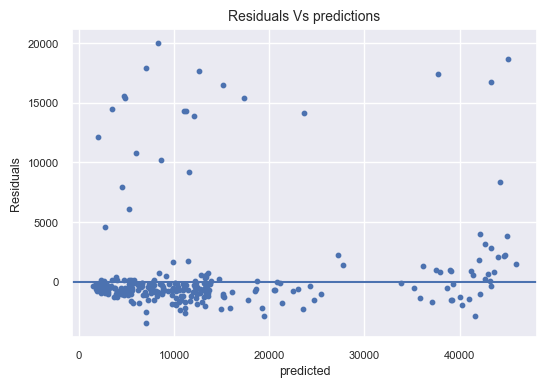

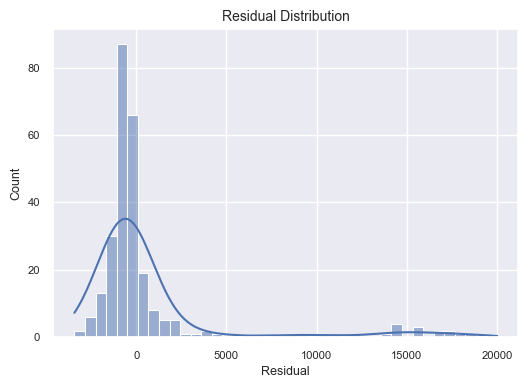

In [131]:
# residual plot
residuals = y_test - test_final_pred

plt.figure(figsize=(6, 4))
plt.scatter(test_final_pred, residuals, s=10)
plt.axhline(0)
plt.title("Residuals Vs predictions")
plt.xlabel("predicted")
plt.ylabel("Residuals")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins= 40, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.show()

Building a predictive system

In [132]:
def predict_insurance_charges(
        model,
        age: float,
        sex: str,
        bmi: float, 
        children: int,
        smoker: str,
        region: str
)-> float:
    
    new_row = pd.DataFrame(
        [{
            "age":age,
            "sex":sex, #male or female
            "bmi": bmi,
            "children": children,
            "smoker":smoker, #yes or nor
            "region": region # northeast | northwest | southeast | southwest
                          
          }

        ]
    )

    return float(model.predict(new_row)[0])

In [133]:
pred = predict_insurance_charges(
    rf_best_log,
    age=35,
    sex="male",
    bmi=29.5,
    children=2,
    smoker="no",
    region="southeast"
)

print("predicted medical insurance cost", round(pred, 2))

predicted medical insurance cost 6108.63
